# CL Intraday Momentum Replication, 2021–2026 (#29)

This notebook summarizes our replication of the crude oil (CL) results in Baltussen, Da, Lammers & Martens (2021), *Hedging Demand and Market Intraday Momentum*. It reads only the files written by the two scripts below. No estimate is computed here that the scripts do not also compute, except the influence checks in Section 4. Run the scripts first, from the repository root:

```bash
python -m src.build_return_features --config config/return_features.yaml   # #28
python -m src.replicate_regressions --config config/replication.yaml       # #29
```

**What is tested.** On each trade date t, the target is the last half-hour return of the held CL contract:

- **LH** = P(t, 13:30) / P(t, 13:00) − 1 (all times Chicago, CT)

The predictors use only prices up to 13:00 CT. P(t−1, 13:30) is the previous trade date's 13:30 price.

| Predictor | Interval (CT) | Meaning |
|---|---|---|
| ONFH | previous 13:30 → 08:30 | overnight plus the first half hour |
| M | 08:30 → 12:30 | middle of the day |
| SLH | 12:30 → 13:00 | second-to-last half hour |
| ROD | previous 13:30 → 13:00 | the whole rest of the day before the last half hour |

We estimate the paper's three models, each with an intercept α:

1. LH = α + β·ONFH + ε (paper Eq. 5)
2. LH = α + β₁·ONFH + β₂·M + β₃·SLH + ε (Eq. 6)
3. LH = α + β·ROD + ε (Eq. 7)

A positive β means **momentum**: a move during the day continues into the close. A negative β means **reversal**. We report each slope with its Newey-West standard error and 95% interval. As in the paper, slopes, adjusted R² and OOS R² are multiplied by 100. For example, a ROD slope × 100 of 1.0 means that a 1% rest-of-day return predicts a 0.01% last-half-hour return. The full write-up is `reports/replication_results.md`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = next(path for path in (Path("."), Path("..")) if (path / "data/processed").exists())
tables = root / "reports/tables"
figures = root / "reports/figures"

features = pd.read_parquet(root / "data/processed/cl_return_features.parquet")
sample = features[features["sample"]].reset_index(drop=True)
manifest = json.loads((tables / "replication.manifest.json").read_text())
regressions = pd.read_csv(tables / "replication_regressions.csv")
vs_paper = pd.read_csv(tables / "replication_vs_paper.csv")
by_year = pd.read_csv(tables / "replication_by_year.csv")
forecasts = pd.read_csv(tables / "replication_oos_forecasts.csv", parse_dates=["trade_date"])
sensitivity = pd.read_csv(tables / "replication_oos_sensitivity.csv")
robustness = pd.read_csv(tables / "replication_robustness.csv")

MODELS = {"onfh": "ONFH", "onfh_m_slh": "ONFH + M + SLH", "rod": "ROD"}
TERMS = {"const": "intercept", "r_onfh": "ONFH", "r_m": "M", "r_slh": "SLH", "r_rod": "ROD"}
pd.set_option("display.float_format", "{:.3f}".format)


def interval(frame: pd.DataFrame, suffix: str = "") -> pd.Series:
	return frame.apply(lambda row: f"[{row[f'ci_low_x100{suffix}']:.2f}, {row[f'ci_high_x100{suffix}']:.2f}]", axis=1)

## 1. Sample

The sample comes from the return features (#28) and contains the trade dates that pass the paper's filters: all reference prices exist, no early close, and volume of at least 100 contracts. The Newey-West lag length is set by the script, and the first out-of-sample forecast follows from the paper's minimum of 500 observations.

In [2]:
excluded = features[~features["sample"]]
pd.Series(
	{
		"trade dates in the sample": len(sample),
		"first and last date": manifest["sample"]["dates"],
		"excluded trade dates": len(excluded),
		"Newey-West lags": manifest["hac_lags_used"],
		"first out-of-sample forecast": manifest["sample"]["first_oos_forecast"],
		"LH daily SD (%)": round(sample["r_lh"].std() * 100, 3),
		"ROD daily SD (%)": round(sample["r_rod"].std() * 100, 3),
	},
	name="value",
).to_frame()

,value
trade dates in the sample,1436
first and last date,2021-01-04 to 2026-10-07
excluded trade dates,12
Newey-West lags,7
first out-of-sample forecast,2023-01-04
LH daily SD (%),0.469
ROD daily SD (%),2.480


In [3]:
excluded[["trade_date", "exclusion_reason"]].reset_index(drop=True)

,trade_date,exclusion_reason
0,2021-11-26,missing p_1300; missing p_1330; early close
1,2021-11-29,missing p_prev_1330
2,2022-11-25,missing p_1300; missing p_1330; early close
3,2022-11-28,missing p_prev_1330
4,2023-11-24,missing p_1300; missing p_1330; early close
5,2023-11-27,missing p_prev_1330
6,2024-11-29,early close
7,2024-12-24,missing p_1300; missing p_1330; early close
8,2024-12-26,missing p_prev_1330
9,2025-11-28,early close


## 2. Full-sample estimates against the paper

The paper's CL values come from Appendix Table B3, Panel B (1987-01-06 to 2020-05-01, 8,336 days). The paper reports t-statistics rather than standard errors, so its standard errors are recovered as |β / t|. The last column is our slope minus the paper's, with the standard error of a difference between independent samples.

In [4]:
slopes = vs_paper.assign(
	model=vs_paper["model"].map(MODELS),
	slope=vs_paper["term"].map(TERMS),
	paper_interval=interval(vs_paper, "_paper"),
	our_interval=interval(vs_paper, "_ours"),
	difference=vs_paper.apply(lambda row: f"{row['difference_x100']:.2f} ({row['difference_se_x100']:.2f})", axis=1),
)
slopes[["model", "slope", "coef_x100_paper", "paper_interval", "coef_x100_ours", "se_x100_ours", "our_interval", "t_stat_ours", "difference"]].rename(
	columns={
		"coef_x100_paper": "paper β×100", "paper_interval": "paper 95% CI", "coef_x100_ours": "our β×100", "se_x100_ours": "our SE×100",
		"our_interval": "our 95% CI", "t_stat_ours": "our t", "difference": "ours − paper (SE)",
	}
)

,model,slope,paper β×100,paper 95% CI,our β×100,our SE×100,our 95% CI,our t,ours − paper (SE)
0,ONFH,ONFH,2.000,"[-3.44, 7.44]",-1.295,0.954,"[-3.16, 0.57]",-1.358,-3.30 (2.94)
1,ONFH + M + SLH,ONFH,2.400,"[-1.80, 6.60]",-1.320,0.935,"[-3.15, 0.51]",-1.411,-3.72 (2.34)
2,ONFH + M + SLH,M,-0.060,"[-3.98, 3.86]",-1.943,1.857,"[-5.58, 1.70]",-1.046,-1.88 (2.73)
3,ONFH + M + SLH,SLH,-13.950,"[-41.57, 13.67]",0.380,4.956,"[-9.33, 10.09]",0.077,14.33 (14.94)
4,ROD,ROD,0.670,"[-4.58, 5.92]",-1.457,0.965,"[-3.35, 0.43]",-1.510,-2.13 (2.85)


In [5]:
fit = regressions.drop_duplicates("model").set_index("model")
paper_fit = vs_paper.drop_duplicates("model").set_index("model")
pd.DataFrame(
	{
		"adj. R² paper (%)": paper_fit["adj_r2_pct_paper"],
		"adj. R² ours (%)": fit["adj_r2_pct"],
		"OOS R² paper (%)": paper_fit["oos_r2_pct_paper"],
		"OOS R² ours (%)": fit["oos_r2_pct"],
		"Clark-West t": fit["clark_west_t"],
		"Clark-West p (one-sided)": fit["clark_west_p"],
		"n": fit["n"],
	}
).rename(index=MODELS)

,adj. R² paper (%),adj. R² ours (%),OOS R² paper (%),OOS R² ours (%),Clark-West t,Clark-West p (one-sided),n
model,,,,,,,
ONFH,0.170,0.238,-0.480,-0.424,0.124,0.451,1436
ONFH + M + SLH,1.250,0.460,-1.770,-1.490,-0.986,0.838,1436
ROD,0.030,0.524,-1.040,0.368,1.002,0.158,1436


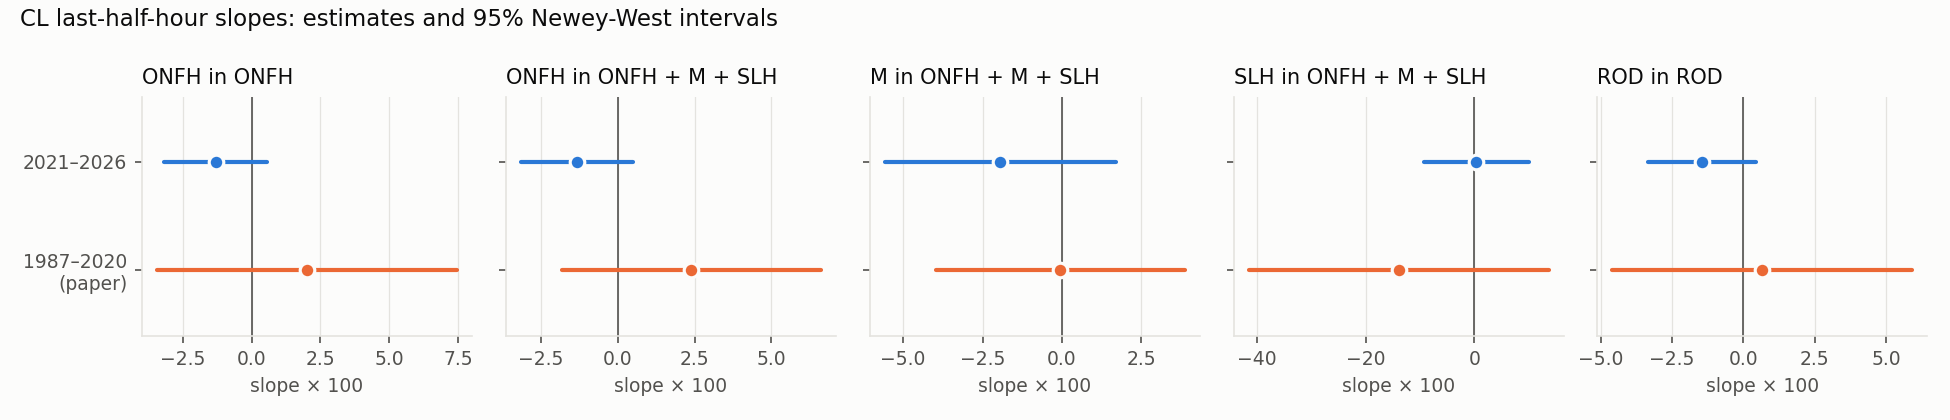

In [6]:
display(Image(filename=figures / "replication_vs_paper.png"))

- **Every 95% interval contains zero.** The point estimates for ONFH, M and ROD are negative, the opposite sign to the paper's, which points to mild reversal rather than momentum.
- **The two periods cannot be told apart.** Each difference from the paper is at most about 1.6 standard errors.
- **Our standard errors are about a third of the paper's**, although we have one sixth of its observations. The write-up discusses one possible cause: extreme returns around the April 2020 negative-price episode at the end of the paper's sample.

## 3. Over time

Calendar-year estimates (the dots in the figure) and 252-day rolling estimates, with 95% bands. The dashed line is the paper's point estimate.

In [7]:
years = by_year[by_year["term"].ne("const")].assign(model=lambda frame: frame["model"].map(MODELS), slope=lambda frame: frame["term"].map(TERMS))
years = years.assign(ci=interval(years))
years.pivot_table(index="year", columns=["model", "slope"], values="ci", aggfunc="first")

model           ONFH   ONFH + M + SLH                                  \
slope           ONFH                M           ONFH              SLH   
year                                                                    
2021   [-8.06, 0.61]    [-3.10, 6.69]  [-8.04, 0.34]  [-18.94, 22.67]   
2022   [-6.29, 2.23]    [-1.14, 6.38]  [-6.62, 2.27]   [-26.22, 4.63]   
2023   [-4.14, 4.36]    [-5.69, 2.64]  [-4.14, 4.39]  [-18.21, 20.00]   
2024   [-3.13, 4.28]    [-5.33, 0.33]  [-3.22, 4.40]  [-15.92, 21.13]   
2025   [-2.11, 2.97]    [-3.33, 4.90]  [-1.78, 3.32]   [-4.19, 27.23]   
2026   [-5.19, 2.35]  [-20.00, -0.70]  [-4.85, 1.68]  [-23.20, 16.81]   

model            ROD  
slope            ROD  
year                  
2021   [-4.68, 1.96]  
2022   [-3.99, 2.60]  
2023   [-3.26, 2.09]  
2024   [-3.23, 1.82]  
2025   [-1.65, 3.70]  
2026   [-8.10, 1.11]

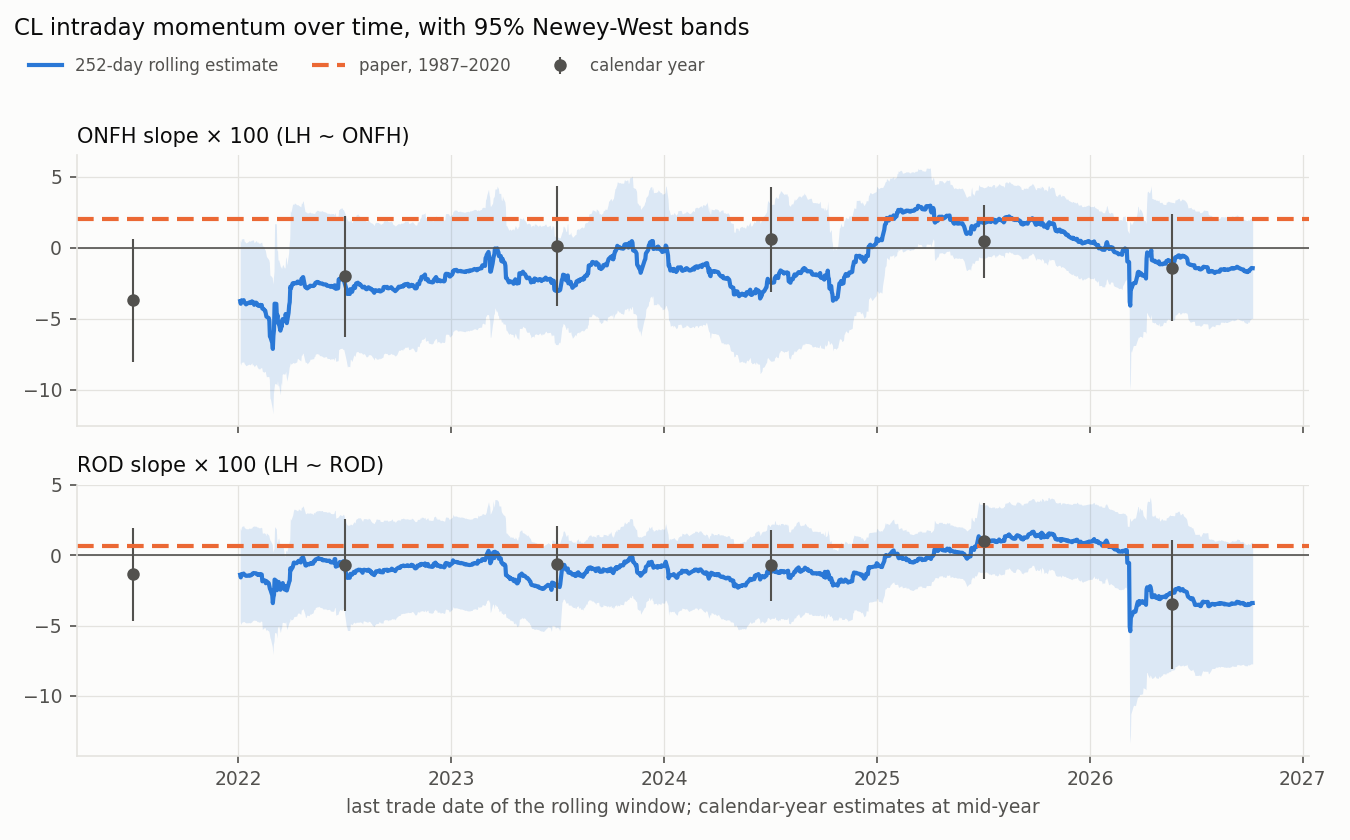

In [8]:
display(Image(filename=figures / "replication_slopes_over_time.png"))

- **ROD** has a negative slope in every year except 2025, and no single year's interval excludes zero.
- **March 2026.** The rolling ROD estimate drops sharply when the rest-of-day moves reach ±15%.

## 4. Out of sample

From 2023-01-04, each model is refit every day on all earlier days and forecasts LH. Each forecast is compared with the historical mean of LH up to the previous day:

- **OOS R²** = 1 − Σ(LH − forecast)² / Σ(LH − historical mean)².
- **Clark-West test**: whether the model's mean squared error is significantly below the historical mean's.

In the figure, a rising line means the model is beating the historical mean.

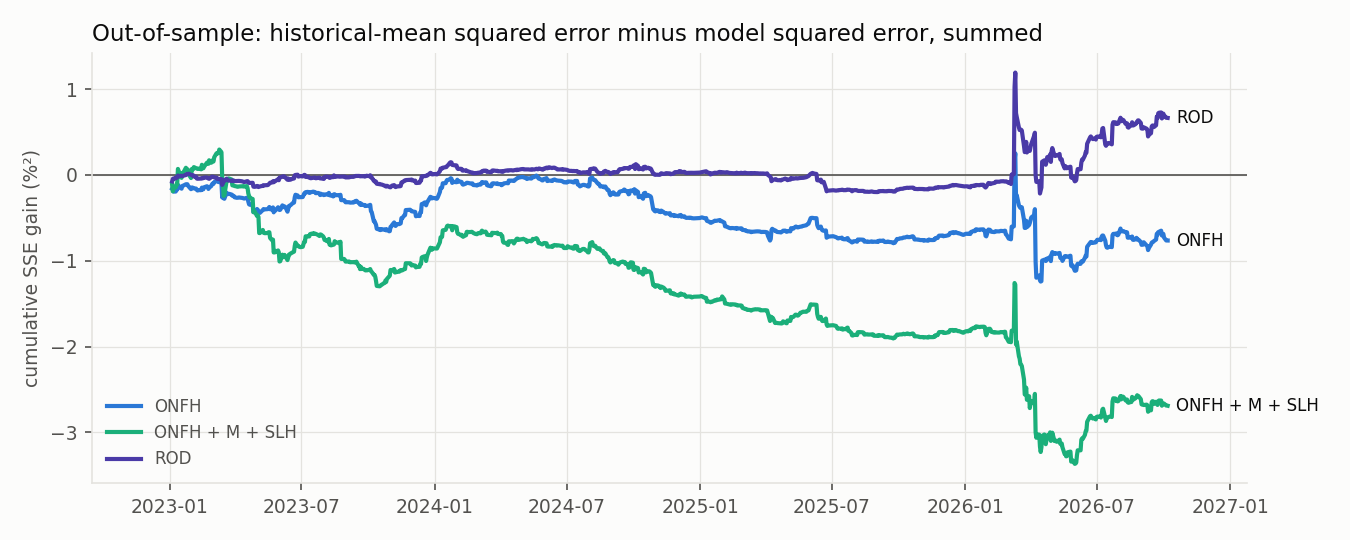

In [9]:
display(Image(filename=figures / "replication_oos_cumulative.png"))

In [10]:
sensitivity.assign(model=sensitivity["model"].map(MODELS)).pivot_table(
	index=["min_train_obs", "first_forecast"], columns="model", values=["oos_r2_pct", "clark_west_p"]
)

clark_west_p                      oos_r2_pct  \
model                                ONFH ONFH + M + SLH   ROD       ONFH   
min_train_obs first_forecast                                                
250           2022-01-03            0.302          0.458 0.281     -0.446   
500           2023-01-04            0.451          0.838 0.158     -0.424   
750           2024-01-05            0.427          0.797 0.166     -0.366   
1000          2025-01-08            0.398          0.709 0.181     -0.241   

                                                    
model                        ONFH + M + SLH    ROD  
min_train_obs first_forecast                        
250           2022-01-03             -1.294 -0.020  
500           2023-01-04             -1.490  0.368  
750           2024-01-05             -1.374  0.494  
1000          2025-01-08             -1.168  0.582

**Where ROD's out-of-sample gain comes from.** The gain on a day is the benchmark's squared error minus the model's squared error, here in squared percent (%²). These lines check how much of the final OOS R² comes from a few days.

In [11]:
rod = forecasts[forecasts["model"].eq("rod")].copy()
rod["gain_pct2"] = ((rod["actual"] - rod["historical_mean"]) ** 2 - (rod["actual"] - rod["forecast"]) ** 2) * 1e4
rod = rod.merge(sample[["trade_date", "r_rod"]], on="trade_date")


def oos_r2(rows: pd.DataFrame) -> float:
	return 100 * (1 - ((rows["actual"] - rows["forecast"]) ** 2).sum() / ((rows["actual"] - rows["historical_mean"]) ** 2).sum())


march_2026 = rod["trade_date"].dt.to_period("M").eq(pd.Period("2026-03"))
largest = rod["gain_pct2"].idxmax()
display(
	pd.Series(
		{
			"OOS R², all forecasts (%)": oos_r2(rod),
			"OOS R², without March 2026 (%)": oos_r2(rod[~march_2026]),
			f"OOS R², without {rod.loc[largest, 'trade_date'].date()} (%)": oos_r2(rod.drop(index=largest)),
			"total gain (%²)": rod["gain_pct2"].sum(),
			"gain from March 2026 (%²)": rod.loc[march_2026, "gain_pct2"].sum(),
		},
		name="ROD",
	).to_frame()
)
rows = pd.concat([rod.nlargest(5, "gain_pct2"), rod.nsmallest(5, "gain_pct2")])
(rows[["trade_date", "r_rod", "actual", "forecast", "gain_pct2"]].assign(r_rod=lambda frame: frame["r_rod"] * 100, actual=lambda frame: frame["actual"] * 100, forecast=lambda frame: frame["forecast"] * 100)
	.rename(columns={"r_rod": "ROD (%)", "actual": "LH (%)", "forecast": "forecast (%)", "gain_pct2": "gain (%²)"}).reset_index(drop=True))

,ROD
"OOS R², all forecasts (%)",0.368
"OOS R², without March 2026 (%)",0.204
"OOS R², without 2026-03-10 (%)",-0.219
total gain (%²),0.664
gain from March 2026 (%²),0.357


,trade_date,ROD (%),LH (%),forecast (%),gain (%²)
0,2026-03-10,-15.437,4.551,0.087,1.013
1,2026-04-17,-10.233,1.283,0.094,0.300
2,2026-07-23,7.346,-1.223,-0.111,0.229
3,2026-03-11,4.782,-1.104,-0.103,0.170
4,2026-04-30,-3.094,1.428,0.019,0.122
5,2026-04-08,-15.534,-0.965,0.210,-0.495
6,2026-03-12,8.609,1.431,-0.177,-0.473
7,2026-07-13,8.668,0.696,-0.139,-0.192
8,2026-03-23,-9.621,-0.553,0.128,-0.181
9,2026-04-14,-6.982,-0.815,0.062,-0.143


- **ONFH and ONFH + M + SLH** lose to the historical mean, as in the paper.
- **ROD's small positive OOS R²** is not significant, and it depends on the first forecast date. Without the single day of 10 March 2026 (ROD −15.4%, LH +4.6%), it turns negative, so it should not be read as evidence that ROD forecasts LH.

## 5. Robustness

Each variant re-estimates every model:

- with other Newey-West lag lengths;
- under the existing roll rule, 3 sessions before expiry, with prices rebuilt from the minute bars;
- without one group of dates: roll dates, Databento degraded dates, the last 3 sessions before expiry, days after a weekend or holiday, or the 1% largest |ROD| days.

The table shows slope × 100 with its standard error in parentheses.

In [12]:
slope_rows = robustness[robustness["term"].ne("const")].assign(
	cell=lambda frame: frame.apply(lambda row: f"{row['coef_x100']:.2f} ({row['se_x100']:.2f})", axis=1),
	column=lambda frame: frame["model"].map(MODELS) + ": " + frame["term"].map(TERMS),
)
columns = list(dict.fromkeys(slope_rows["column"]))
table = slope_rows.pivot_table(index="variant", columns="column", values="cell", aggfunc="first")[columns]
fits = robustness.drop_duplicates(["variant", "model"]).pivot_table(index="variant", columns="model", values="oos_r2_pct").rename(columns=lambda model: f"OOS R² {MODELS[model]} (%)")
order = list(dict.fromkeys(robustness["variant"]))
table.join(robustness.drop_duplicates("variant").set_index("variant")[["n", "dropped"]]).join(fits).reindex(order)

,ONFH: ONFH,ONFH + M + SLH: ONFH,ONFH + M + SLH: M,ONFH + M + SLH: SLH,ROD: ROD,n,dropped,OOS R² ONFH (%),OOS R² ONFH + M + SLH (%),OOS R² ROD (%)
variant,,,,,,,,,,
baseline,-1.30 (0.95),-1.32 (0.94),-1.94 (1.86),0.38 (4.96),-1.46 (0.97),1436,0,-0.424,-1.490,0.368
hac_lags_0,-1.30 (0.99),-1.32 (0.97),-1.94 (1.93),0.38 (5.79),-1.46 (1.01),1436,0,NaN,NaN,NaN
hac_lags_1,-1.30 (1.02),-1.32 (1.01),-1.94 (1.95),0.38 (5.46),-1.46 (1.03),1436,0,NaN,NaN,NaN
hac_lags_5,-1.30 (1.00),-1.32 (0.98),-1.94 (1.88),0.38 (5.04),-1.46 (0.98),1436,0,NaN,NaN,NaN
hac_lags_10,-1.30 (0.90),-1.32 (0.88),-1.94 (1.85),0.38 (4.92),-1.46 (0.93),1436,0,NaN,NaN,NaN
hac_lags_20,-1.30 (0.85),-1.32 (0.83),-1.94 (1.83),0.38 (4.69),-1.46 (0.89),1436,0,NaN,NaN,NaN
pre_expiry_roll_3_sessions,-1.32 (0.95),-1.34 (0.93),-2.01 (1.86),0.51 (4.97),-1.49 (0.96),1436,0,-0.449,-1.475,0.398
exclude_roll_dates,-0.88 (0.98),-0.90 (0.95),-2.40 (1.87),2.78 (5.06),-1.29 (1.00),1367,69,-0.642,-1.142,0.114
exclude_degraded_dates,-1.37 (0.96),-1.40 (0.94),-2.05 (1.86),0.21 (4.98),-1.55 (0.98),1424,12,-0.330,-1.302,0.510


In [13]:
threshold = sample["r_rod"].abs().quantile(0.99)
extreme = sample[sample["r_rod"].abs().gt(threshold)][["trade_date", "contract_id", "r_rod", "r_lh"]]
print(f"{len(extreme)} days with |ROD| above {threshold * 100:.1f}% (dropped in exclude_extreme_rod):")
extreme.assign(r_rod=extreme["r_rod"] * 100, r_lh=extreme["r_lh"] * 100).rename(columns={"r_rod": "ROD (%)", "r_lh": "LH (%)"}).reset_index(drop=True)

15 days with |ROD| above 7.5% (dropped in exclude_extreme_rod):


,trade_date,contract_id,ROD (%),LH (%)
0,2022-03-01,CLJ2022,8.981,-0.672
1,2022-03-09,CLJ2022,-11.987,0.046
2,2022-03-17,CLJ2022,8.231,0.292
3,2022-07-05,CLQ2022,-9.769,1.759
4,2022-07-12,CLQ2022,-7.524,-0.612
5,2025-06-13,CLN2025,7.540,-0.014
6,2026-03-05,CLJ2026,8.220,0.161
7,2026-03-06,CLJ2026,13.128,-0.808
8,2026-03-10,CLJ2026,-15.437,4.551
9,2026-03-12,CLJ2026,8.609,1.431


- **The sign does not change.** The negative slope holds under every lag length, both roll rules, and every exclusion.
- **The roll rule barely matters.** Changing it moves the held contract on 127 days but the ROD slope by only 0.03.
- **Extreme days matter most.** Dropping the 15 largest |ROD| days halves the ROD slope, so part of the negative estimate comes from reversals on crisis days, mostly in 2022 and 2026.

## Conclusion

In 2021–2026 there is **no evidence of intraday momentum in CL**. The slopes are small and slightly negative, every confidence interval includes zero, and only the ROD model beats the historical mean out of sample. That gain is not statistically significant and comes largely from March 2026. This matches the paper's own non-significant CL result. The new hypotheses (#31–#33) therefore ask whether the overnight and daytime parts of ROD behave differently, and whether the reversal on extreme days is a volatility-regime effect.